
# Blockwise coregistration -- Panamint Valley Example

Often, biases are spatially variable, and a "global" shift may not be enough to coregister a DEM properly.
In the `sphx_glr_basic_examples_plot_nuth_kaab.py` example, we saw that the method improved the alignment significantly, but there were still possibly nonlinear artefacts in the result.
Clearly, nonlinear coregistration approaches are needed.
One solution is :class:`xdem.coreg.BlockwiseCoreg`, a helper to run any ``Coreg`` class over an arbitrarily small grid, and then "puppet warp" the DEM to fit the reference best.

The ``BlockwiseCoreg`` class runs in five steps:

1. Generate a subdivision grid to divide the DEM in N blocks.
2. Run the requested coregistration approach in each block.
3. Extract each result as a source and destination X/Y/Z point.
4. Interpolate the X/Y/Z point-shifts into three shift-rasters.
5. Warp the DEM to apply the X/Y/Z shifts.


In [1]:
import geoutils as gu

import matplotlib.pyplot as plt
import numpy as np
from geoutils.raster.distributed_computing import MultiprocConfig

import xdem

Open 3DEP and QUAKES-I point clouds.
3DEP point cloud serves as the reference dataset, and the QUAKES-I data is to be aligned with the 3DEP. 



In [ ]:
reference_dem = xdem.DEM("PV_data/Clipped_full/Cl_z1_PV_3DEP_dem_res_tif.tif")
dem_to_be_aligned = xdem.DEM("PV_data/Clipped_full/Cl_z1_PV_quakDEMicp_cropfa_tif.tif")
print(dem_to_be_aligned.info(stats=True))
print(reference_dem.info(stats=True))

dem_to_be_aligned = dem_to_be_aligned.reproject(reference_dem)
print(dem_to_be_aligned.info(stats=True))
print(reference_dem.info(stats=True))
print(type(reference_dem))
print(type(dem_to_be_aligned))

Driver:               GTiff 
Opened from file:     PV_data/Clipped_full/Cl_z1_PV_quakDEMicp_cropfa_tif_Copy.tif 
Filename:             PV_data/Clipped_full/Cl_z1_PV_quakDEMicp_cropfa_tif_Copy.tif 
Loaded?               False 
Modified since load?  False 
Grid size:            890, 901
Number of bands:      1
Data types:           float32
Coordinate system:    ['EPSG:32611']
Nodata value:         -9999.0
Pixel interpretation: Area
Pixel size:           1.5584500000000476, 1.5584500000003796
Upper left corner:    468835.752302451, 4020578.336008695
Lower right corner:   470222.77280245104, 4021982.4994586953

Statistics:
Mean                   : 686.52
Median                 : 679.83
Max                    : 811.49
Min                    : 590.68
Sum                    : 265830928.00
Sum of squares         : 183734042624.00
90th percentile        : 767.26
LE90                   : 174.13
NMAD                   : 69.41
RMSE                   : 688.84
Standard deviation     : 56.51
Valid co

In [ ]:
## NOT USED 

'''glacier_outlines = gu.Vector("PV_data/PV_masks.shp")
print("opened mask...")
# Create a stable ground mask (not glacierized) to mark "inlier data"
inlier_mask = ~glacier_outlines.create_mask(reference_dem)
print("created mask...")

plt_extent = [
    reference_dem.bounds.left,
    reference_dem.bounds.right,
    reference_dem.bounds.bottom,
    reference_dem.bounds.top,
]
'''

opened mask...
created mask...


In [17]:
print(type(reference_dem))
print(type(dem_to_be_aligned))
print(type(inlier_mask))

<class 'xdem.dem.DEM'>
<class 'xdem.dem.DEM'>
<class 'geoutils.raster.raster.Mask'>


Compute the difference between the two point clouds prior to alignment:

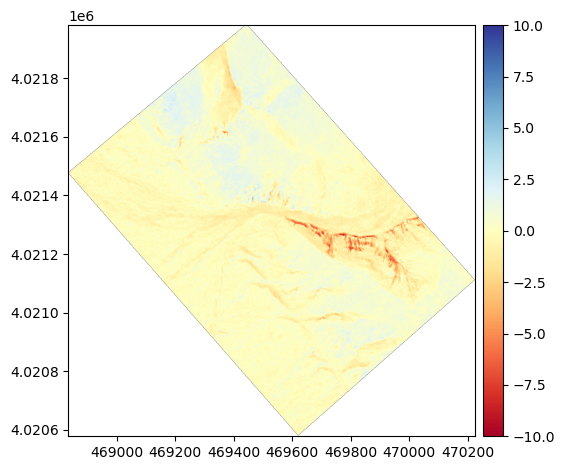

In [18]:
diff_before = reference_dem - dem_to_be_aligned

diff_before.plot(cmap="RdYlBu", vmin=-10, vmax=10)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
print(diff_before.data)
print(type(diff_before.data.flatten()))
print(np.shape(diff_before.data.flatten()))


flat = diff_before.data.flatten()
#print(flat)

#print(max(flat))
#plt.title(f"Histogram of Initial Vertical Difference")
#plt.hist(diff_before.data.flatten(), bins = np.linspace(-4, 4, 1),color='skyblue')
#plt.show()

[[-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 ...
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]]
<class 'numpy.ma.MaskedArray'>
(801890,)
[-- -- -- ... -- -- --]
--


Horizontal and vertical shifts can be estimated using :class:`xdem.coreg.NuthKaab`.
Let's prepare a coregistration class with a tiling configuration
BlockwiseCoreg is also available without mp_config but with parent_path parameters



In [ ]:
mp_config = MultiprocConfig(chunk_size=200, outfile="aligned_dem.tif")
blockwise = xdem.coreg.BlockwiseCoreg(xdem.coreg.NuthKaab(), mp_config=mp_config, )
print("Done")
print(blockwise)

Done


Coregistration is performed with the ``.fit()`` method.



In [21]:
print(reference_dem)
print(dem_to_be_aligned)
print(inlier_mask)

[[-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 ...
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]]
[[-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 ...
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]
 [-- -- -- ... -- -- --]]
[[True True True ... True True True]
 [True True True ... True True True]
 [True True True ... True True True]
 ...
 [True True True ... False False False]
 [True True True ... False False False]
 [True True True ... False False False]]


In [22]:
## seems to have issue with 'big' rasters 
blockwise.fit(reference_dem, dem_to_be_aligned) #,inlier_mask)
aligned_DEM = blockwise.apply()

print(type(aligned_DEM))
#aligned_dem = xdem.DEM("block_aligned_dem.tif")

<class 'geoutils.raster.raster.Raster'>


The estimated shifts can be visualized by applying the coregistration to a completely flat surface.
This shows the estimated shifts that would be applied in elevation;
additional horizontal shifts will also be applied if the method supports it.



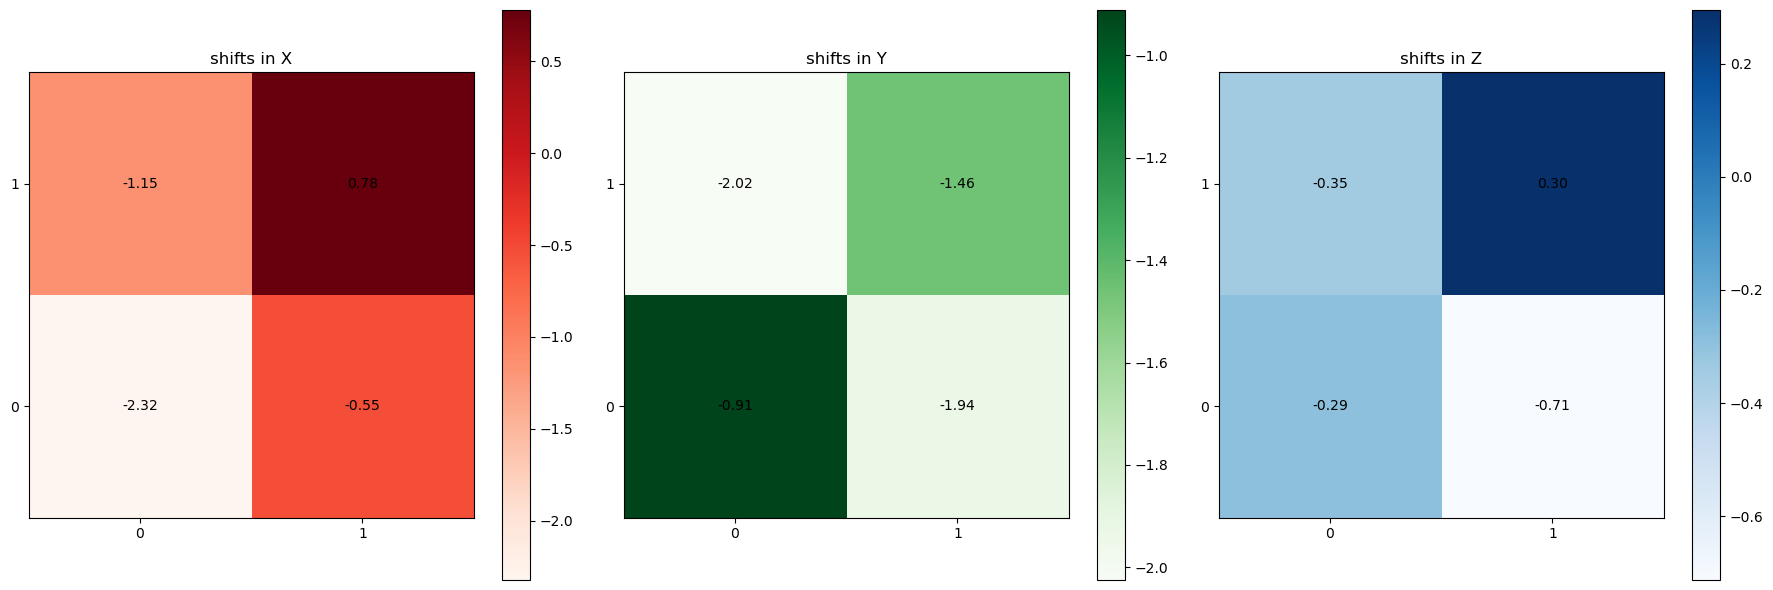

In [23]:
rows, cols, _ = blockwise.shape_tiling_grid

matrix_x = np.full((rows, cols), np.nan)
matrix_y = np.full((rows, cols), np.nan)
matrix_z = np.full((rows, cols), np.nan)

for key, value in blockwise.meta["outputs"].items():
    row, col = map(int, key.split("_"))
    matrix_x[row, col] = value["shift_x"]
    matrix_y[row, col] = value["shift_y"]
    matrix_z[row, col] = value["shift_z"]


def plot_heatmap(matrix, title, cmap, ax):
    im = ax.imshow(matrix, cmap=cmap)
    for (i, j), val in np.ndenumerate(matrix):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="black")
    ax.set_title(title)
    ax.set_xticks(np.arange(cols))
    ax.set_yticks(np.arange(rows))
    ax.invert_yaxis()
    plt.colorbar(im, ax=ax)


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
plot_heatmap(matrix_x, "shifts in X", "Reds", axes[0])
plot_heatmap(matrix_y, "shifts in Y", "Greens", axes[1])
plot_heatmap(matrix_z, "shifts in Z", "Blues", axes[2])

plt.tight_layout()
plt.show()

Then, the new difference can be plotted to validate that it improved.



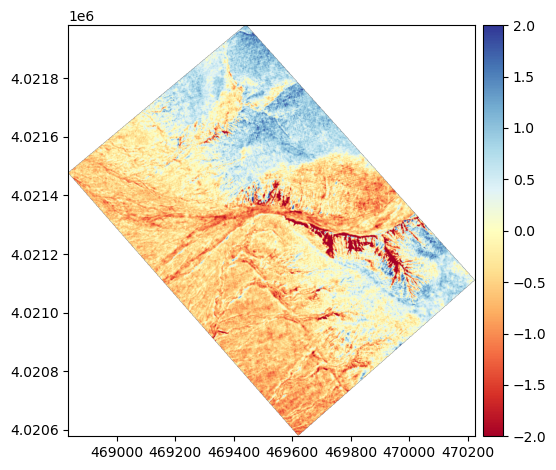

In [24]:
diff_after = reference_dem - aligned_DEM

diff_after.plot(cmap="RdYlBu", vmin=-2, vmax=2)
plt.show()

We can compare the NMAD to validate numerically that there was an improvement:



In [25]:
print(f"Error before: {gu.stats.nmad(diff_before[inlier_mask]):.2f} m")
print(f"Error after: {gu.stats.nmad(diff_after[inlier_mask]):.2f} m")

Error before: 0.61 m
Error after: 0.80 m


In [26]:
#diff_after.save("PV_data/Zones/zones_redo/z2_diff_after.tif", driver='GTiff')
#diff_before.save("PV_data/Zones/zones_redo/z2_diff_before.tif", driver='GTiff')

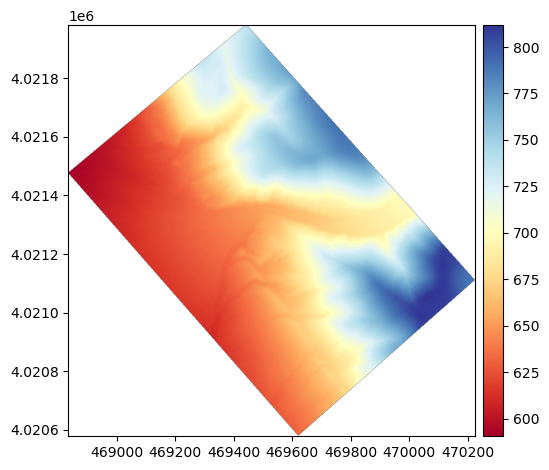

In [29]:
diff = xdem.DEM("PV_data/Zones/zone1_Bw/z1_diff_after.tif")
aligned_DEM = reference_dem - diff

aligned_DEM.plot(cmap="RdYlBu")


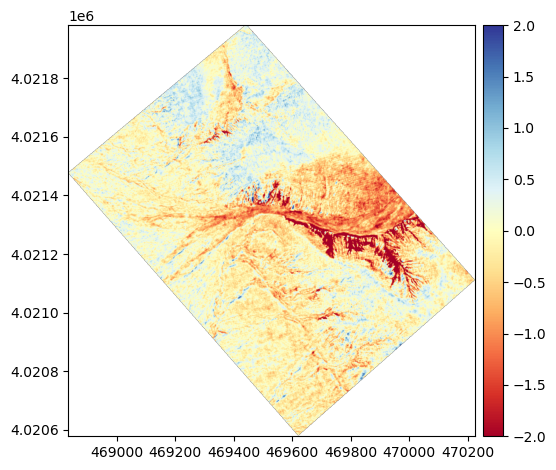

In [31]:
dff_af = reference_dem - aligned_DEM
dff_af.plot(cmap="RdYlBu", vmin=-2, vmax=2)

In [34]:
print(f"Error before: {gu.stats.nmad(diff_before[inlier_mask]):.2f} m")
print(f"Error after: {gu.stats.nmad(dff_af[inlier_mask]):.2f} m")

Error before: 0.61 m
Error after: 0.34 m


In [ ]:
#aligned_DEM.save("PV_data/Zones/zone1_Bw/z1_bw_aligned.tif", driver='GTiff')